In [95]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import os
import copy

from diffusion_mlp_cnn.models.utils import Data
from diffusion_mlp_cnn.models.MLP import MLPDiffusionRegressor

In [96]:
plt.rcParams.update({
    # "text.usetex": True,
    # "font.family": "serif",
    "text.usetex": False,
    "mathtext.fontset": "stix",
    "font.family": "STIXGeneral",
    "axes.linewidth": 2,
    "xtick.major.width": 2,
    "ytick.major.width": 2,
    "xtick.minor.width": 2,
    "ytick.minor.width": 2,
})

# Load data

### Training and single-step validation data

In [97]:
initializations = ["gaussian", "uniform", "cosine"]
training_data = {}
for size in [1925, 14700, 48825]:
    training_data.update({size: Data(
            initializations,
            path="../datasets/training_size_" + str(size) +
            "/training_data",
            model_type="MLP"
        )
    })
    print(f"Input training data shape (N_samples, Nx): "
          f"{training_data[size].X_numpy.shape}")
    print(f"Output training data shape (N_samples, Nx): "
          f"{training_data[size].Y_numpy.shape}")
    print(f"Training data dtype (input, output): "
          f"({training_data[size].X.dtype}, {training_data[size].Y.dtype})\n")

Input training data shape (N_samples, Nx): (1925, 201)
Output training data shape (N_samples, Nx): (1925, 201)
Training data dtype (input, output): (torch.float32, torch.float32)

Input training data shape (N_samples, Nx): (14700, 201)
Output training data shape (N_samples, Nx): (14700, 201)
Training data dtype (input, output): (torch.float32, torch.float32)

Input training data shape (N_samples, Nx): (48825, 201)
Output training data shape (N_samples, Nx): (48825, 201)
Training data dtype (input, output): (torch.float32, torch.float32)



In [98]:
initializations = ["gaussian", "uniform", "cosine"]
validation_data = {}
for size in [1925, 14700, 48825]:
    validation_data.update({size: Data(
            initializations,
            path="../datasets/training_size_" + str(size) +
            "/validation_data",
            model_type="MLP"
        )
    })
    print(f"Input single-step validation data shape (N_samples, Nx): "
          f"{validation_data[size].X_numpy.shape}")
    print(f"Output single-step validation data shape (N_samples, Nx): "
          f"{validation_data[size].Y_numpy.shape}")
    print(f"Single-step validation data dtype (input, output): "
          f"({validation_data[size].X.dtype}, {validation_data[size].Y.dtype})\n")

Input single-step validation data shape (N_samples, Nx): (350, 201)
Output single-step validation data shape (N_samples, Nx): (350, 201)
Single-step validation data dtype (input, output): (torch.float32, torch.float32)

Input single-step validation data shape (N_samples, Nx): (1400, 201)
Output single-step validation data shape (N_samples, Nx): (1400, 201)
Single-step validation data dtype (input, output): (torch.float32, torch.float32)

Input single-step validation data shape (N_samples, Nx): (3150, 201)
Output single-step validation data shape (N_samples, Nx): (3150, 201)
Single-step validation data dtype (input, output): (torch.float32, torch.float32)



### Full time series data

Initializations: Gaussian, uniform block and cosine

# Load trained MLP

In [99]:
os.makedirs("figures", exist_ok=True)

In [100]:
width = 128
depth = 2
epochs = {}
training_MSE_loss = {}
training_L2_error = {}
validation_L2_error = {}
mlp_models = {}
for size in [1925, 14700, 48825]:
    epochs.update({size: {}})
    training_MSE_loss.update({size: {}})
    training_L2_error.update({size: {}})
    validation_L2_error.update({size: {}})
    mlp_models.update({size: {}})
    for activation in ["relu", "tanh"]:
        perf_data = np.loadtxt(
            "training_performance/mlp_" + activation +
            "_size_" + str(size) + ".txt",
            dtype=np.float32
        )
        epochs[size].update({activation: perf_data[:, 0]})
        training_MSE_loss[size].update({activation: perf_data[:, 1]})
        training_L2_error[size].update({activation: perf_data[:, 2]})
        validation_L2_error[size].update({activation: perf_data[:, 3]})
        model = MLPDiffusionRegressor(
            training_data[size].Nx,
            width,
            depth,
            activation=activation
        )
        model.load_state_dict(
            torch.load("trained_models/mlp_" + activation + "_size_" +
                       str(size) + ".pt", map_location="cpu",
                       weights_only=True)
        )
        mlp_models[size].update({activation: model})

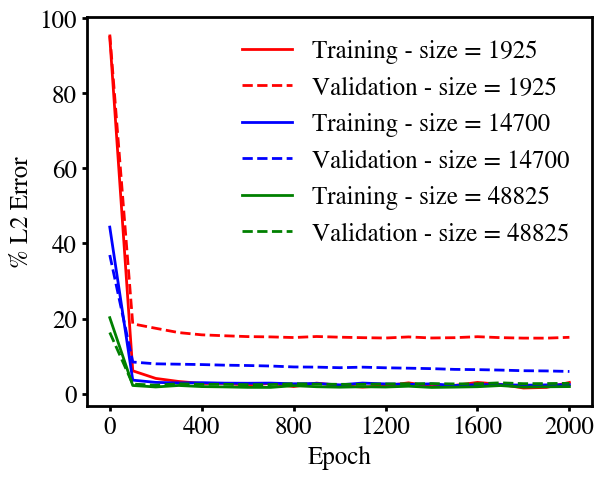

In [101]:
activation = "relu"
fig = plt.figure(2)
ax = fig.add_axes([0.20, 0.18, 0.79, 0.81])
ax.plot(epochs[1925][activation], training_L2_error[1925][activation] * 100, linewidth=2,
        color="red", linestyle="solid", label=r"Training - size = 1925")
ax.plot(epochs[1925][activation], validation_L2_error[1925][activation] * 100, linewidth=2,
        color="red", linestyle="dashed", label=r"Validation - size = 1925")
ax.plot(epochs[14700][activation], training_L2_error[14700][activation] * 100, linewidth=2,
        color="blue", linestyle="solid", label=r"Training - size = 14700")
ax.plot(epochs[14700][activation], validation_L2_error[14700][activation] * 100, linewidth=2,
        color="blue", linestyle="dashed", label=r"Validation - size = 14700")
ax.plot(epochs[48825][activation], training_L2_error[48825][activation] * 100, linewidth=2,
        color="green", linestyle="solid", label=r"Training - size = 48825")
ax.plot(epochs[48825][activation], validation_L2_error[48825][activation] * 100, linewidth=2,
        color="green", linestyle="dashed", label=r"Validation - size = 48825")
ax.set_xlabel(r"Epoch", fontsize=18)
ax.set_ylabel(r"% L2 Error", fontsize=18)
ax.tick_params(axis="both", labelsize=18)
ax.yaxis.set_major_locator(MaxNLocator(nbins=6))
ax.xaxis.set_major_locator(MaxNLocator(nbins=6))
ax.legend(loc="best", frameon=False, fontsize=18)
plt.savefig("figures/training_performance_mlp_data_size_relu.pdf")
plt.show()

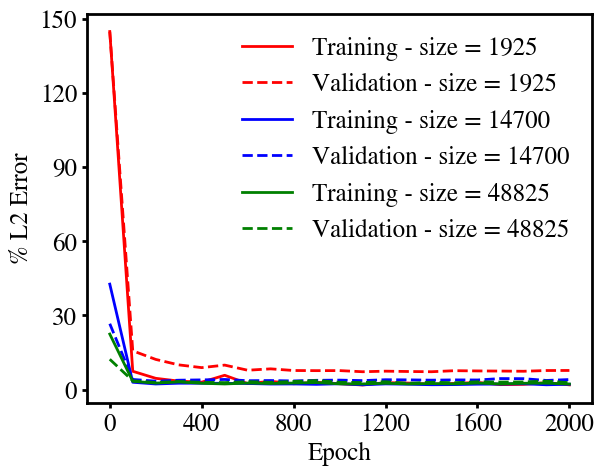

In [102]:
activation = "tanh"
fig = plt.figure(2)
ax = fig.add_axes([0.20, 0.18, 0.79, 0.81])
ax.plot(epochs[1925][activation], training_L2_error[1925][activation] * 100, linewidth=2,
        color="red", linestyle="solid", label=r"Training - size = 1925")
ax.plot(epochs[1925][activation], validation_L2_error[1925][activation] * 100, linewidth=2,
        color="red", linestyle="dashed", label=r"Validation - size = 1925")
ax.plot(epochs[14700][activation], training_L2_error[14700][activation] * 100, linewidth=2,
        color="blue", linestyle="solid", label=r"Training - size = 14700")
ax.plot(epochs[14700][activation], validation_L2_error[14700][activation] * 100, linewidth=2,
        color="blue", linestyle="dashed", label=r"Validation - size = 14700")
ax.plot(epochs[48825][activation], training_L2_error[48825][activation] * 100, linewidth=2,
        color="green", linestyle="solid", label=r"Training - size = 48825")
ax.plot(epochs[48825][activation], validation_L2_error[48825][activation] * 100, linewidth=2,
        color="green", linestyle="dashed", label=r"Validation - size = 48825")
ax.set_xlabel(r"Epoch", fontsize=18)
ax.set_ylabel(r"% L2 Error", fontsize=18)
ax.tick_params(axis="both", labelsize=18)
ax.yaxis.set_major_locator(MaxNLocator(nbins=6))
ax.xaxis.set_major_locator(MaxNLocator(nbins=6))
ax.legend(loc="best", frameon=False, fontsize=18)
plt.savefig("figures/training_performance_mlp_data_size_tanh.pdf")
plt.show()

# Auto-regressive testing

In [103]:
l2_error_time = {}
mass_err_mlp = {}
mass_err_fdm = {}
u_pred = {}
u_fdm = {}
for size in [1925, 14700, 48825]:
    l2_error_time.update({size: {}})
    mass_err_mlp.update({size: {}})
    u_pred.update({size: {}})
    for activation in ["relu", "tanh"]:
        l2_error_time[size].update({activation: {}})
        mass_err_mlp[size].update({activation: {}})
        u_pred[size].update({activation: {}})
        model = mlp_models[size][activation]
        model.eval()
        with torch.inference_mode():
            for init_type in initializations:
                data = np.load(
                    "../datasets/training_size_" + str(size) +
                    "/testing_data/" + init_type +
                    ".npz"
                )
                u = data["u"]
                Nx = data["Nx"]
                snaps = data["snaps"]
                u_tensor = torch.from_numpy(u)
                u_pred_tensor = u_tensor.clone().detach()
                for snap in range(1, u_tensor.shape[0]):
                    u_pred_tensor[snap] = model(
                        u_pred_tensor[snap - 1]
                    )
                diff = u_pred_tensor.detach().numpy() - u
                l2_error = np.linalg.norm(diff, axis=1) /\
                    (np.linalg.norm(u, axis=1) + 1e-10)
                l2_error_time[size][activation].update(
                    {init_type: l2_error}
                )
                u_pred[size][activation].update(
                    {init_type: u_pred_tensor.detach().numpy()}
                )
                u_fdm.update({init_type: u})
                mass_fdm = np.sum(u, axis=1)
                mass_err_fdm.update(
                    {init_type: (mass_fdm - mass_fdm[0]) / mass_fdm[0]}
                )
                mass_mlp = np.sum(
                    u_pred[size][activation][init_type], axis=1
                )
                mass_err_mlp[size][activation].update(
                    {init_type: (mass_mlp - mass_mlp[0]) / mass_mlp[0]}
                )
times = np.arange(0, snaps, 1)  # All must have same time dimension

In [104]:
linestyles = ["solid" for _ in range(3)] +\
    ["dashed" for _ in range(3)] +\
    ["dotted" for _ in range(3)]
colors = ["red", "green", "blue"] * 3

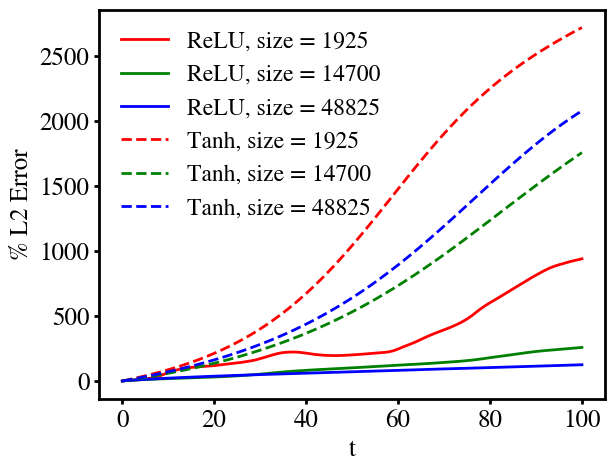

In [105]:
init_type = "gaussian"
activation = "tanh"
fig = plt.figure(2)
ax = fig.add_axes([0.20, 0.18, 0.79, 0.81])
itr = 0
for size in [1925, 14700, 48825]:
    ax.plot(
        times,
        l2_error_time[size]["relu"][init_type] * 100,
        linewidth=2,
        color=colors[itr],
        linestyle=linestyles[itr],
        label=f"ReLU, size = {size}"
    )
    itr += 1
for size in [1925, 14700, 48825]:
    ax.plot(
        times,
        l2_error_time[size]["tanh"][init_type] * 100,
        linewidth=2,
        color=colors[itr],
        linestyle=linestyles[itr],
        label=f"Tanh, size = {size}"
    )
    itr += 1
ax.set_xlabel(r"t", fontsize=18)
ax.set_ylabel(r"% L2 Error", fontsize=18)
ax.tick_params(axis="both", labelsize=18)
ax.yaxis.set_major_locator(MaxNLocator(nbins=6))
ax.xaxis.set_major_locator(MaxNLocator(nbins=6))
ax.legend(loc="best", frameon=False, fontsize=17)
plt.savefig("figures/autoregressive_training_size_mlp.pdf")
plt.show()